In [ ]:
!nvidia-smi

Thu Nov 12 12:07:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Import Required Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")
print("TensorFlow Version:", tf.__version__)

# Check GPU
print("Available GPU:", tf.config.list_physical_devices('GPU'))

All Libraries Imported Successfully!
TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Load CIFAR-10 Dataset

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Dataset Loaded Successfully!")

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1795s 11us/step
Dataset Loaded Successfully!
Training Images: (50000, 32, 32, 3)
Training Labels: (50000, 1)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000, 1)


In [ ]:
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

print("Total Classes:", len(class_names))
print("Class Names:", class_names)

Total Classes: 10
Class Names: ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']


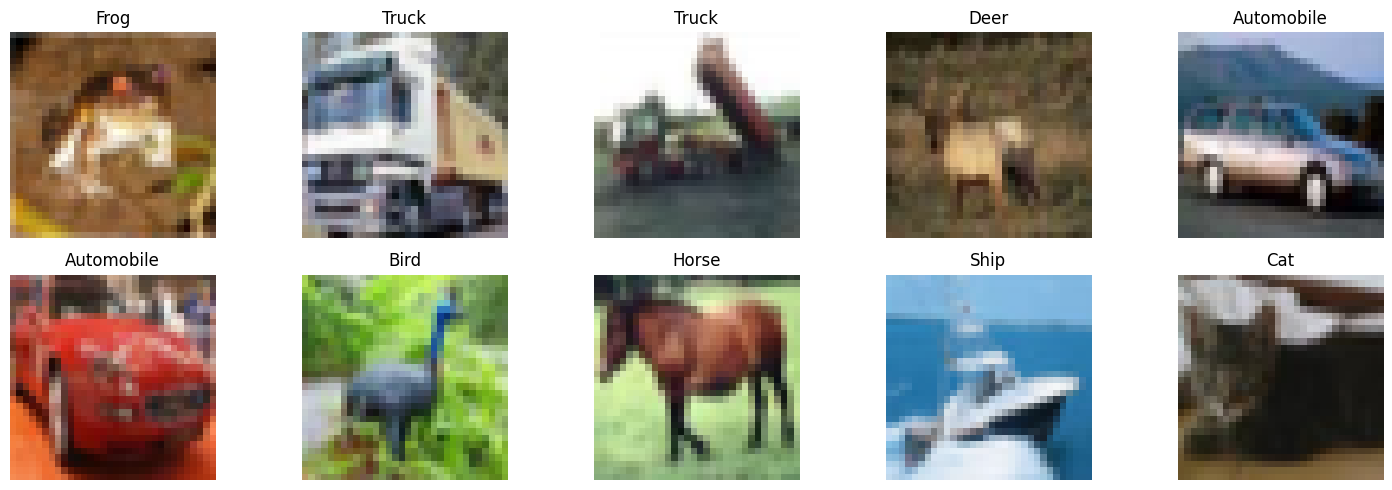

In [ ]:
# Display 10 CIFAR-10 Images

plt.figure(figsize=(15, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])

    label = y_train[i][0]
    plt.title(class_names[label])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Inspect One Training Image

image = X_train[0]
label = y_train[0][0]

print("Image Shape:", image.shape)
print("Image Data Type:", image.dtype)
print("Image Label:", label)
print("Class Name:", class_names[label])

print("Minimum Pixel Value:", image.min())
print("Maximum Pixel Value:", image.max())

Image Shape: (32, 32, 3)
Image Data Type: uint8
Image Label: 6
Class Name: Frog
Minimum Pixel Value: 0
Maximum Pixel Value: 255


In [ ]:
# Normalize Image Pixel Values

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Normalization Completed!")

print("Training Data Minimum:", X_train.min())
print("Training Data Maximum:", X_train.max())

print("Testing Data Minimum:", X_test.min())
print("Testing Data Maximum:", X_test.max())

print("Training Data Type:", X_train.dtype)

Normalization Completed!
Training Data Minimum: 0.0
Training Data Maximum: 1.0
Testing Data Minimum: 0.0
Testing Data Maximum: 1.0
Training Data Type: float32


In [ ]:
# Check Labels Information

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

print("Training Labels Data Type:", y_train.dtype)
print("Testing Labels Data Type:", y_test.dtype)

print("First 10 Training Labels:")
print(y_train[:10].flatten())

Training Labels Shape: (50000, 1)
Testing Labels Shape: (10000, 1)
Training Labels Data Type: uint8
Testing Labels Data Type: uint8
First 10 Training Labels:
[6 9 9 4 1 1 2 7 8 3]


In [ ]:
# Convert labels into 1D arrays

y_train = y_train.flatten()
y_test = y_test.flatten()

# Check updated shapes

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

print("First 10 Training Labels:")
print(y_train[:10])

Training Labels Shape: (50000,)
Testing Labels Shape: (10000,)
First 10 Training Labels:
[6 9 9 4 1 1 2 7 8 3]


In [ ]:
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

print("\nTraining Samples Match:",
      len(X_train) == len(y_train))

print("Testing Samples Match:",
      len(X_test) == len(y_test))

Training Images: (50000, 32, 32, 3)
Training Labels: (50000,)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000,)

Training Samples Match: True
Testing Samples Match: True


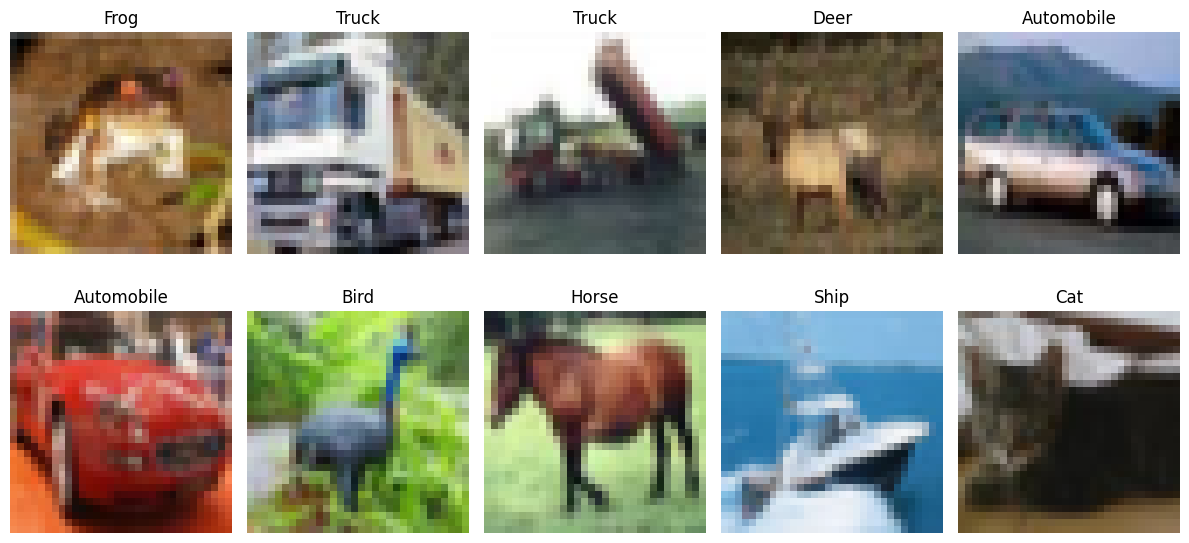

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Build CNN Model - First Convolution Block

model = tf.keras.Sequential()

# Input Layer
model.add(tf.keras.layers.Input(shape=(32, 32, 3)))

# First Conv2D Layer
model.add(tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
))

# Batch Normalization
model.add(tf.keras.layers.BatchNormalization())

# Max Pooling
model.add(tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2)
))

print("First CNN Block Created Successfully!")

First CNN Block Created Successfully!


In [ ]:
# Second Convolution Block

model.add(tf.keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
))

model.add(tf.keras.layers.BatchNormalization())

model.add(tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2)
))

print("Second CNN Block Created Successfully!")

Second CNN Block Created Successfully!


In [ ]:
# Third Convolution Block

model.add(tf.keras.layers.Conv2D(
    filters=128,
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
))

model.add(tf.keras.layers.BatchNormalization())

model.add(tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2)
))

print("Third CNN Block Created Successfully!")

Third CNN Block Created Successfully!


In [ ]:
# Flatten Layer

model.add(tf.keras.layers.Flatten())

print("Flatten Layer Added Successfully!")

Flatten Layer Added Successfully!


In [ ]:
# First Dense Layer

model.add(tf.keras.layers.Dense(
    128,
    activation='relu'
))

print("Dense Layer Added Successfully!")

Dense Layer Added Successfully!


In [ ]:
# Dropout Layer

model.add(tf.keras.layers.Dropout(0.5))

print("Dropout Layer Added Successfully!")

Dropout Layer Added Successfully!


In [ ]:
# Second Dense Layer

model.add(tf.keras.layers.Dense(
    64,
    activation='relu'
))

print("Second Dense Layer Added Successfully!")

Second Dense Layer Added Successfully!


In [ ]:
# Output Layer

model.add(tf.keras.layers.Dense(
    10,
    activation='softmax'
))

print("Output Layer Added Successfully!")

Output Layer Added Successfully!


In [ ]:
# Display CNN Model Summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,322 (1.39 MB)

 Trainable params: 364,874 (1.39 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Compile CNN Model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [ ]:
# Verify GPU Availability

print("Available GPUs:", tf.config.list_physical_devices('GPU'))

print("\nModel Compilation Status: Ready")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Model Compilation Status: Ready


In [ ]:
# Train CNN Model

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.3864 - loss: 1.7058 - val_accuracy: 0.4387 - val_loss: 1.5858
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5276 - loss: 1.3215 - val_accuracy: 0.3474 - val_loss: 2.1604
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5984 - loss: 1.1300 - val_accuracy: 0.5967 - val_loss: 1.1204
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6501 - loss: 0.9987 - val_accuracy: 0.6299 - val_loss: 1.0154
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6869 - loss: 0.9013 - val_accuracy: 0.6705 - val_loss: 0.9658
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7183 - loss: 0.8123 - val_accuracy: 0.5663 - val_loss: 1.4268
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7390 - loss: 0.7480 - val_accuracy: 0.6087 - val_loss: 1.1923
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7617 - loss: 0.6868 - val_accuracy: 

In [ ]:
# Evaluate CNN Model on Testing Data

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7541 - loss: 0.8294

Test Loss: 0.8293551802635193
Test Accuracy: 75.41000247001648 %


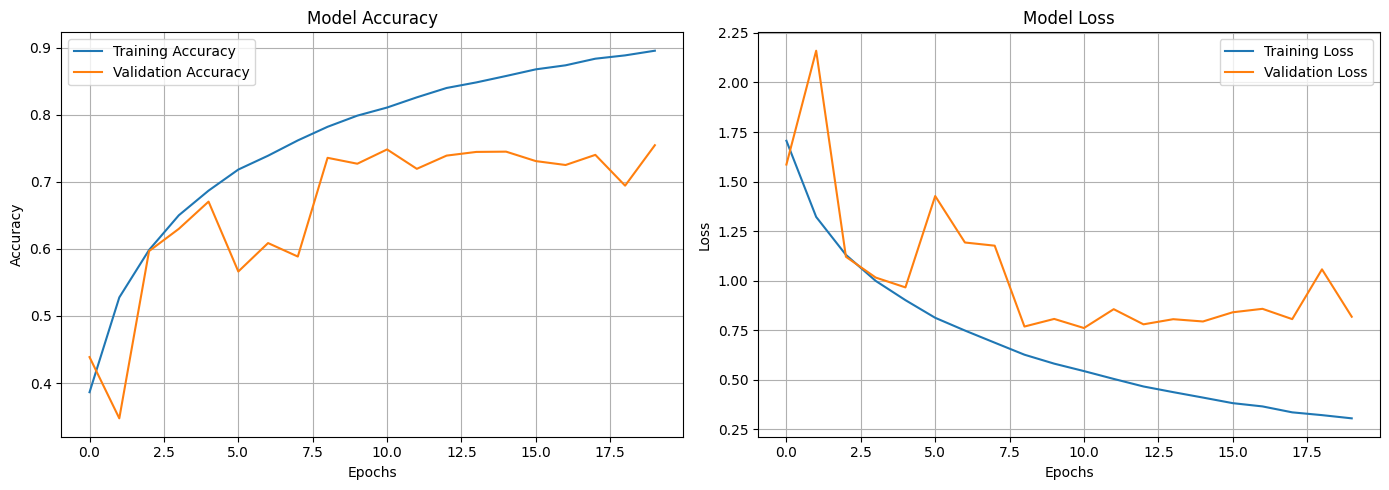

In [ ]:
# Plot Accuracy and Loss Graphs

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

# Loss Graph
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step


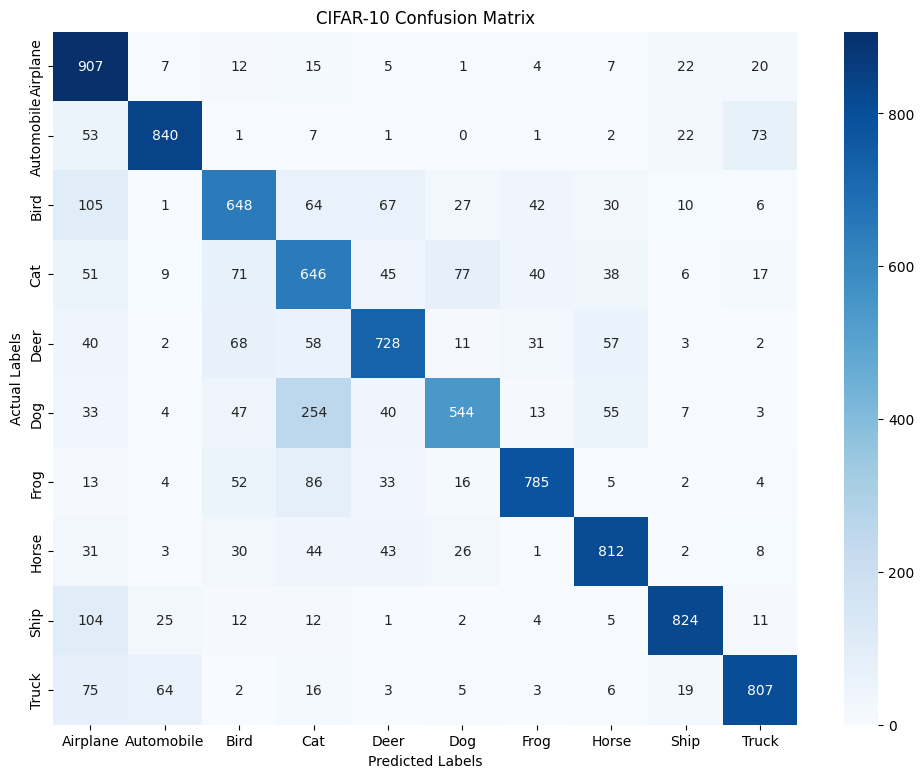

In [ ]:
# Import Required Libraries

from sklearn.metrics import confusion_matrix

# Make Predictions

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

# Create Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

# Visualize Confusion Matrix

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('CIFAR-10 Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')

plt.show()

In [ ]:
# Import Classification Report

from sklearn.metrics import classification_report

# Generate Classification Report

report = classification_report(
    y_test,
    y_pred,
    target_names=class_names
)

print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.64      0.91      0.75      1000
  Automobile       0.88      0.84      0.86      1000
        Bird       0.69      0.65      0.67      1000
         Cat       0.54      0.65      0.59      1000
        Deer       0.75      0.73      0.74      1000
         Dog       0.77      0.54      0.64      1000
        Frog       0.85      0.79      0.82      1000
       Horse       0.80      0.81      0.81      1000
        Ship       0.90      0.82      0.86      1000
       Truck       0.85      0.81      0.83      1000

    accuracy                           0.75     10000
   macro avg       0.77      0.75      0.75     10000
weighted avg       0.77      0.75      0.75     10000



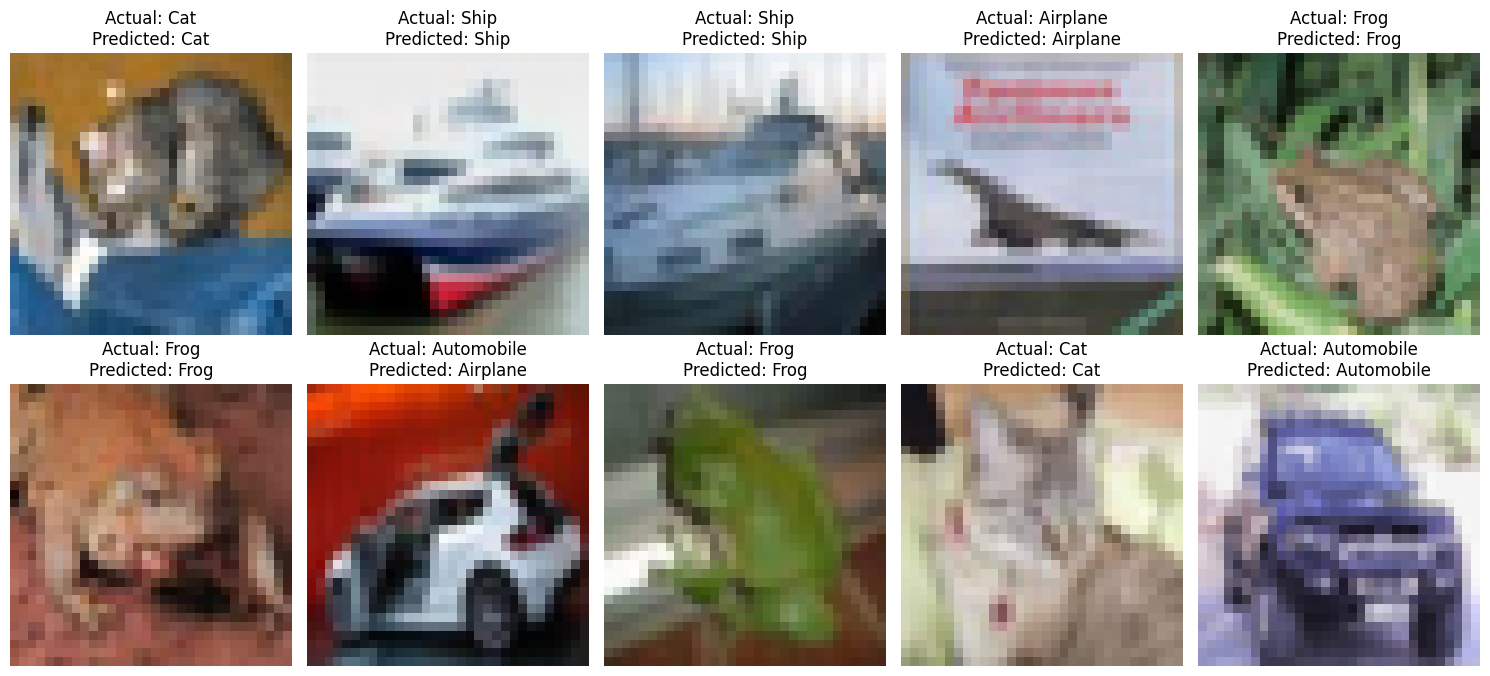

In [ ]:
# Display Actual vs Predicted Images

plt.figure(figsize=(15, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i])

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

Total Misclassified Images: 2459


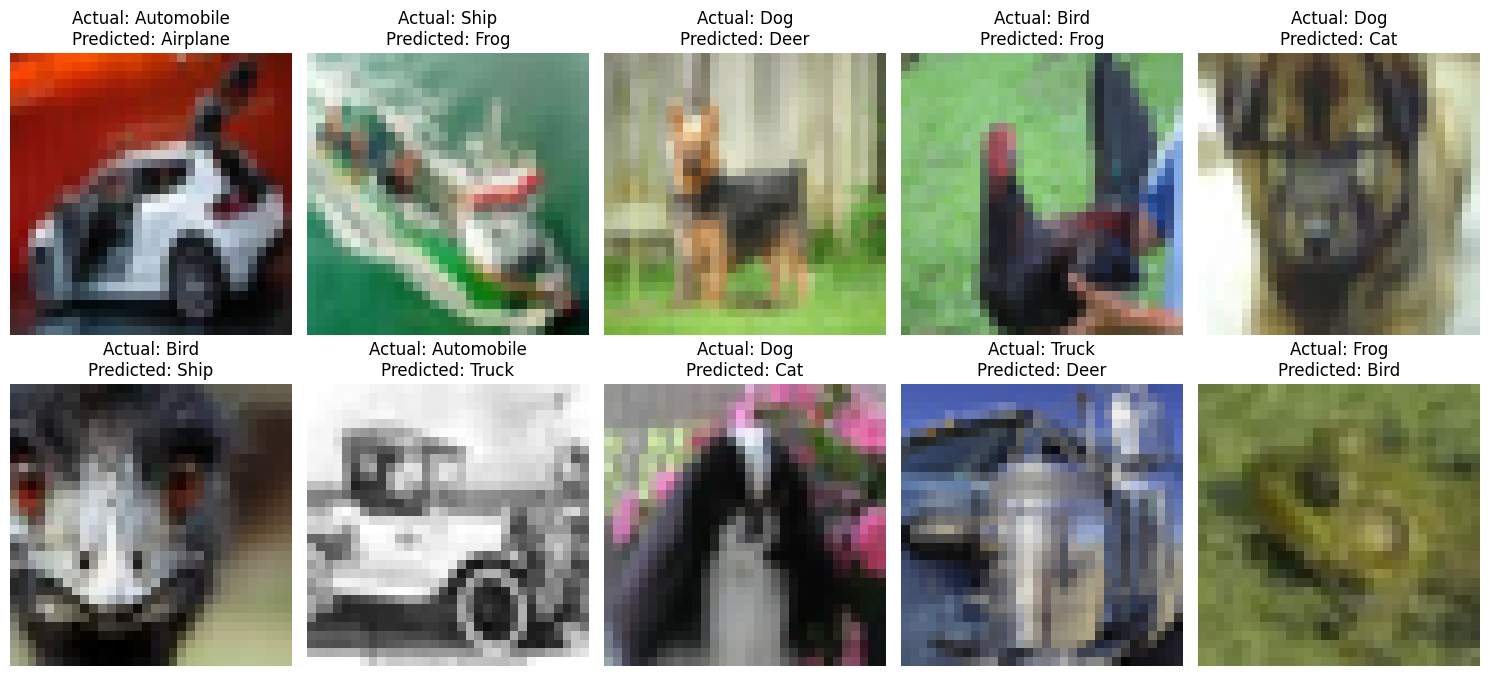

In [ ]:
# Find Misclassified Images

misclassified_indices = np.where(y_test != y_pred)[0]

print("Total Misclassified Images:",
      len(misclassified_indices))

# Display First 10 Misclassified Images

plt.figure(figsize=(15, 7))

for i, index in enumerate(misclassified_indices[:10]):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index])

    actual = class_names[y_test[index]]
    predicted = class_names[y_pred[index]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

Saving Pixelated Tabby Kitten Portrait.png to Pixelated Tabby Kitten Portrait.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


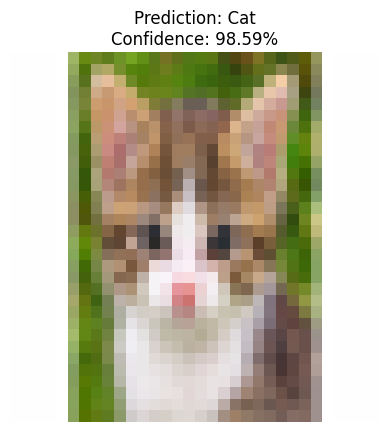

Predicted Class: Cat
Confidence: 98.59%


In [ ]:
# Import Required Libraries

from google.colab import files
from PIL import Image

# Upload Image

uploaded = files.upload()

# Get Uploaded Image Name

image_name = next(iter(uploaded))

# Open and Resize Image

img = Image.open(image_name).convert('RGB')

img = img.resize((32, 32))

# Convert Image into Array

img_array = np.array(img).astype('float32') / 255.0

# Add Batch Dimension

img_array = np.expand_dims(img_array, axis=0)

# Make Prediction

prediction = model.predict(img_array)

predicted_class = np.argmax(prediction[0])

confidence = np.max(prediction[0]) * 100

# Display Uploaded Image

plt.imshow(img)

plt.axis('off')

plt.title(
    f"Prediction: {class_names[predicted_class]}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

print("Predicted Class:", class_names[predicted_class])
print("Confidence:", f"{confidence:.2f}%")

In [ ]:
# Save CNN Model

model.save('CIFAR10_CNN_Image_Classification.keras')

print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!


In [ ]:
# Download Trained Model

from google.colab import files

files.download('CIFAR10_CNN_Image_Classification.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>